<a href="https://colab.research.google.com/github/Prateek0325/Machine-Learning-Projects/blob/main/Property_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Property Price Prediction (House Price Estimation)**

# **Problem Statement**

Property prices are influenced by multiple factors such as house size, location, age, and overall condition. Accurately estimating property prices is important for buyers, sellers, real estate companies, and financial institutions. Manual estimation often leads to incorrect pricing and poor decision-making

The objective of this project is to build a **regression-based machine learning model** to predict property prices using historical housing data and to identify the most important factors influencing house prices.



# **Objectives of the Project**

* Understand property price patterns

* Perform basic data preprocessing

* Conduct minimal but meaningful Exploratory Data Analysis (EDA)

* Build regression-based machine learning models

* Evaluate model performance using regression metrics

* Identify key price-influencing features

 **Uploading file**

In [ ]:
from google.colab import files
upload = files.upload()

Saving train.csv to train (1).csv


**Loading/Reading the Dataset**

In [ ]:
import pandas as pd
df = pd.read_csv("train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**Importing Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

**Relevant columns**

In [ ]:
cols = ['GrLivArea', 'Neighborhood', 'YearBuilt', 'OverallQual', 'BedroomAbvGr', 'FullBath', 'SalePrice']
df = df[cols]

**Checking missing values**

In [ ]:
df.isnull().sum()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   GrLivArea     1460 non-null   int64 
 1   Neighborhood  1460 non-null   object
 2   YearBuilt     1460 non-null   int64 
 3   OverallQual   1460 non-null   int64 
 4   BedroomAbvGr  1460 non-null   int64 
 5   FullBath      1460 non-null   int64 
 6   SalePrice     1460 non-null   int64 
dtypes: int64(6), object(1)
memory usage: 80.0+ KB


**Feature and Target Variables**

In [ ]:
x = df.drop('SalePrice', axis=1)
y = df['SalePrice']

**Numericala and Categorical Columns**

In [ ]:
cat_cols = ['Neighborhood']
num_cols = ['GrLivArea', 'YearBuilt', 'OverallQual', 'BedroomAbvGr', 'FullBath']

Preprocessing (Encoding + Scalling)

In [ ]:
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

**Train-Test Split**

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

Train models

In [ ]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

results = {}


In [ ]:
for name, model in models.items():
  pipeline = Pipeline([
      ("preprocessor", preprocessor),
      ("model", model)
  ])

  pipeline.fit(x_train, y_train)
  y_pred = pipeline.predict(x_test)

  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)

  results[name] = (rmse, r2)

**Model Evaluation Output**

In [ ]:
for model, values in results.items():
  print(f"{model}")
  print(f"RMSE: {values[0]:.2f}")
  print(f"R^2 Score: {values[1]:.2f}")
  print("-" * 30)

Linear Regression
RMSE: 37883.03
R^2 Score: 0.81
------------------------------
Decision Tree
RMSE: 42459.82
R^2 Score: 0.76
------------------------------
Random Forest
RMSE: 29837.46
R^2 Score: 0.88
------------------------------


# **Exploratory Data Analysis (EDA)**

**Price Distrubution**

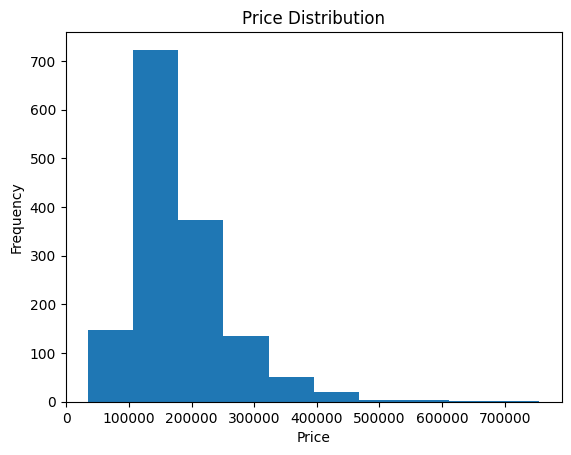

In [ ]:
plt.hist(df['SalePrice'])
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Price Distribution")
plt.show()

**House Size vs Price**

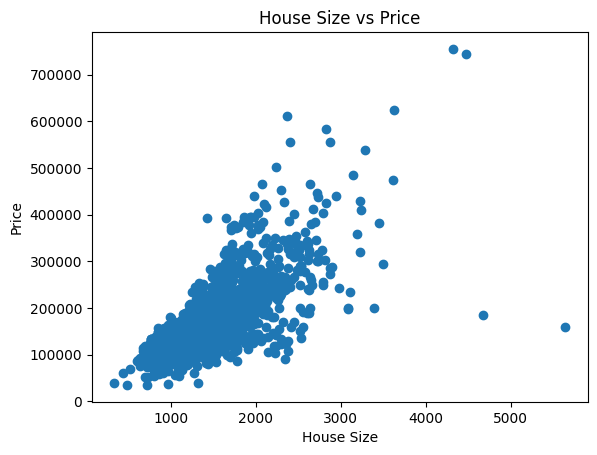

In [ ]:
plt.scatter(df['GrLivArea'], df["SalePrice"])
plt.xlabel("House Size")
plt.ylabel("Price")
plt.title("House Size vs Price")
plt.show()

**Price by Location**

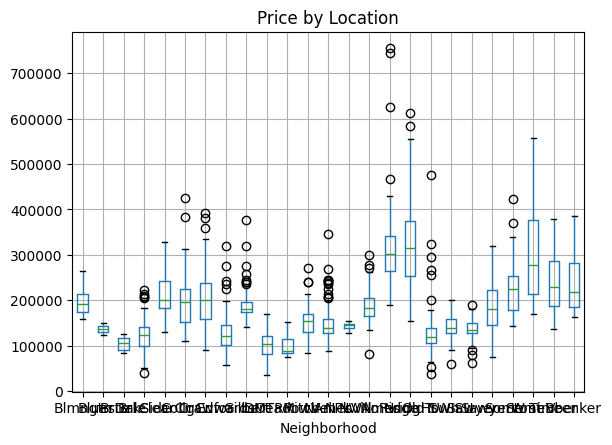

In [ ]:
df.boxplot(column='SalePrice', by='Neighborhood')
plt.title("Price by Location")
plt.suptitle("")
plt.show()

**Property Age vs Price**

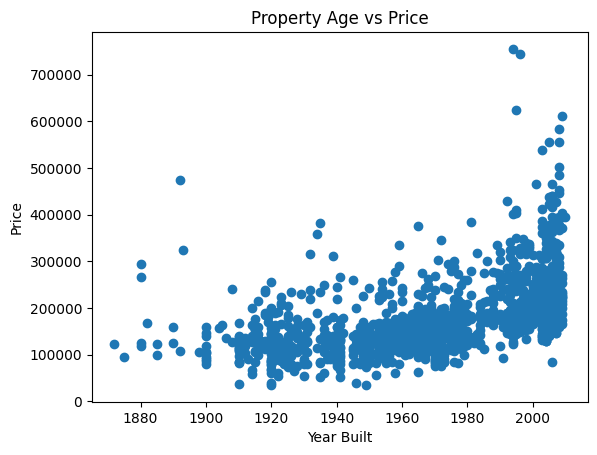

In [ ]:
plt.scatter(df['YearBuilt'], df['SalePrice'])
plt.xlabel("Year Built")
plt.ylabel('Price')
plt.title("Property Age vs Price")
plt.show()

**Actual vs Predicted Prices(Random Forest)**

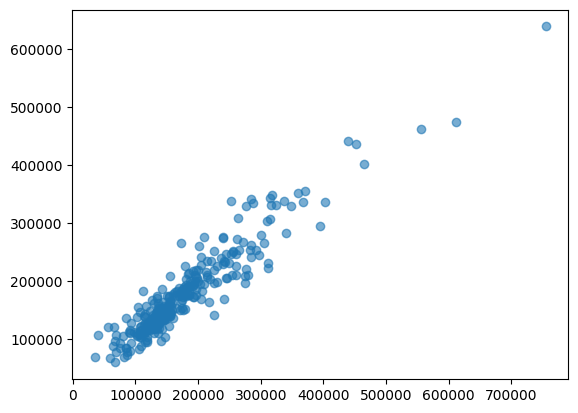

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()

#scatter plot for prediction
plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    label="Predicted Prices"
)

**Feature Importance**

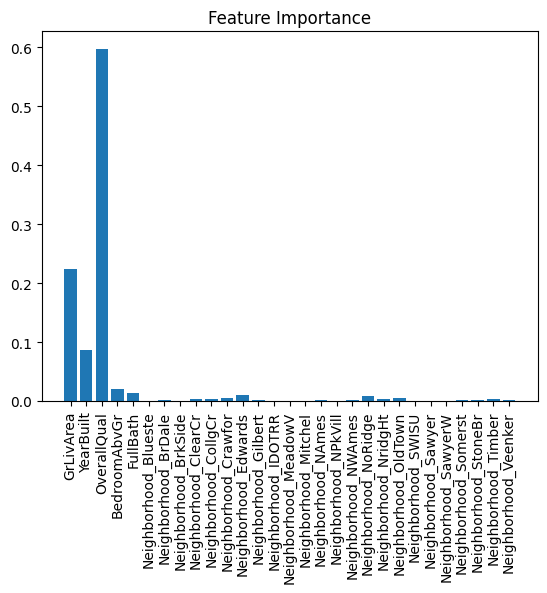

In [ ]:
rf_model = pipeline.named_steps['model']

feature_names = (
    num_cols +
    list(
        pipeline.named_steps["preprocessor"]
        .named_transformers_['cat']
        .get_feature_names_out(cat_cols)
    )
)

plt.bar(feature_names, rf_model.feature_importances_)
plt.xticks(rotation=90)
plt.title("Feature Importance")
plt.show()